# Need to pull data from the NWS

In [2]:
print('Hello, World!')

Hello, World!


In [3]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt
from datetime import datetime

In [4]:
def download_asos_data(station_id, start_date, end_date):
    """
    Downloads historical ASOS data from the IEM API for a specific station.
    https://mesonet.agron.iastate.edu/request/download.phtml

    Args:
        station_id (str): The ICAO station identifier (e.g., 'KDSM').
        start_date (datetime): The start date of the data.
        end_date (datetime): The end date of the data.

    Returns:
        pd.DataFrame: A DataFrame containing the ASOS observations.
                      Returns None if the download fails.
    """
    # URL for the IEM ASOS data
    url = (f"https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py?"
           f"station={station_id}&"
           f"data=all&"
           f"year1={start_date.year}&month1={start_date.month}&day1={start_date.day}&"
           f"year2={end_date.year}&month2={end_date.month}&day2={end_date.day}&"
           f"tz=Etc/UTC&format=onlycomma&latlon=no&missing=M")

    print(f"Downloading data from: {url}")
    
    try:
        # Use requests to get the data
        response = requests.get(url, timeout=60)
        response.raise_for_status()  # Raise an exception for bad status codes
        
        # Read the content into a pandas DataFrame
        df = pd.read_csv(pd.io.common.StringIO(response.text), na_values='M')
        
        # Convert the 'valid' column to datetime objects
        df['valid'] = pd.to_datetime(df['valid'])
        
        # Set 'valid' as the index for time-series analysis
        df.set_index('valid', inplace=True)
        
        print(f"Successfully downloaded {len(df)} observations for {station_id}.")
        return df
        
    except requests.exceptions.RequestException as e:
        print(f"Error downloading data: {e}")
        return None
    except pd.errors.ParserError as e:
        print(f"Error parsing CSV data: {e}")
        return None

def download_daily_data(station_id, start_date, end_date):
    """
    Downloads daily summary ASOS data from the IEM API for a specific station.
    https://mesonet.agron.iastate.edu/request/daily.phtml?network=SC_ASOS

    Args:
        station_id (str): The ICAO station identifier (e.g., 'KDSM').
        start_date (datetime): The start date of the data.
        end_date (datetime): The end date of the data.

    Returns:
        pd.DataFrame: A DataFrame containing the ASOS observations.
                      Returns None if the download fails.
    """
    
    # URL for the IEM ASOS data
    url = (f"https://mesonet.agron.iastate.edu/cgi-bin/request/daily.py?"
           f"network=WA_ASOS&"
           f"stations={station_id}&"
           f"year1={start_date.year}&month1={start_date.month}&day1={start_date.day}&"
           f"year2={end_date.year}&month2={end_date.month}&day2={end_date.day}&"
           f"na=M&format=csv")

    print(f"Downloading data from: {url}")
    
    try:
        # Use requests to get the data
        response = requests.get(url, timeout=60)
        response.raise_for_status()  # Raise an exception for bad status codes
        
        # Read the content into a pandas DataFrame
        df = pd.read_csv(pd.io.common.StringIO(response.text), na_values='M')
        
        # Convert the 'day' column to datetime objects
        df['day'] = pd.to_datetime(df['day'])
        
        # Set 'day' as the index for time-series analysis
        df.set_index('day', inplace=True)
        
        print(f"Successfully downloaded {len(df)} observations for {station_id}.")
        return df
        
    except requests.exceptions.RequestException as e:
        print(f"Error downloading data: {e}")
        return None
    except pd.errors.ParserError as e:
        print(f"Error parsing CSV data: {e}")
        return None


In [5]:
# establish params for api
station = 'OLM'  # CAE - Columbia Metropolitan Airport, SC and CUB - Jim Hamilton Owens Airport off of Rosewood.
start = dt.datetime(2026, 9, 1)
end = dt.datetime(2026, 9, 7)

# create daily data
daily_df = download_daily_data(station, start, end)
daily_df

# create hourly data
hourly_df = download_asos_data(station, start, end)
hourly_df.dropna(subset=['tmpf'], inplace=True)
hourly_df.head()


Successfully downloaded 7 observations for OLM.
Successfully downloaded 1815 observations for OLM.


,station,tmpf,dwpf,relh,drct,sknt,p01i,alti,mslp,vsby,...,wxcodes,ice_accretion_1hr,ice_accretion_3hr,ice_accretion_6hr,peak_wind_gust,peak_wind_drct,peak_wind_time,feel,metar,snowdepth
valid,,,,,,,,,,,,,,,,,,,,,
2026-09-01 00:54:00,OLM,77.0,51.0,40.26,50.0,4.0,0.0,29.77,1008.0,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.0,KOLM 010054Z 05004KT 10SM CLR 25/11 A2977 RMK ...,NaN
2026-09-01 01:54:00,OLM,77.0,51.0,40.26,NaN,NaN,0.0,29.76,1007.7,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.0,KOLM 010154Z 10SM CLR 25/11 A2976 RMK AO2 SLP0...,NaN
2026-09-01 02:54:00,OLM,71.0,52.0,51.07,NaN,NaN,0.0,29.76,1007.6,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.0,KOLM 010254Z 10SM CLR 22/11 A2976 RMK AO2 SLP0...,NaN
2026-09-01 03:54:00,OLM,67.0,51.0,56.44,NaN,NaN,0.0,29.78,1008.2,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67.0,KOLM 010354Z AUTO 10SM CLR 19/11 A2978 RMK AO2...,NaN
2026-09-01 04:54:00,OLM,64.0,51.0,62.64,NaN,NaN,0.0,29.79,1008.6,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.0,KOLM 010454Z AUTO 10SM CLR 18/11 A2979 RMK AO2...,NaN


In [6]:
hourly_df.columns

Index(['station', 'tmpf', 'dwpf', 'relh', 'drct', 'sknt', 'p01i', 'alti',
       'mslp', 'vsby', 'gust', 'skyc1', 'skyc2', 'skyc3', 'skyc4', 'skyl1',
       'skyl2', 'skyl3', 'skyl4', 'wxcodes', 'ice_accretion_1hr',
       'ice_accretion_3hr', 'ice_accretion_6hr', 'peak_wind_gust',
       'peak_wind_drct', 'peak_wind_time', 'feel', 'metar', 'snowdepth'],
      dtype='str')

In [7]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(hourly_df['tmpf'], color='red', label='Temp')
ax1.scatter(hourly_df.index, hourly_df['tmpf'], color='red', s=10)
ax1.plot(hourly_df['dwpf'], color='blue', label='Dew Point')

ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature (°F)', color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.legend(loc='upper left')

# Create a secondary y-axis for humidity
ax2 = ax1.twinx()
ax2.plot(hourly_df['relh'], color='green', linestyle='--', label='Avg. Rel. Humidity (%)')
ax2.set_ylim(0, 100)
ax2.set_ylabel('Relative Humidity (%)', color='green')
ax2.tick_params(axis='y', labelcolor='green')
ax2.legend(loc='upper right')



# # Create a third y-axis for precipitation (can also be a bar plot)
# ax3 = ax1.twinx()
# # Offset the spine of ax3 to the right to avoid overlap with ax2
# ax3.spines['right'].set_position(('outward', 60))
# ax3.bar(daily_df.index,daily_df['precip_in'], color='grey', alpha=0.5, width=0.8, label='Precip. (in)')
# ax3.set_ylabel('Precipitation (in)', color='gray')
# ax3.set_ylim(0,2)
# ax3.tick_params(axis='y', labelcolor='gray')
# ax3.legend(loc='lower right')

# ax1.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7, zorder=0)
# ax2.grid(True, which='major', color='g', linestyle='--', linewidth=0.5, alpha=0.7, zorder=0)

# start = pd.to_datetime('2026-09-04 00:00:00')
# end = pd.to_datetime('2026-09-06 11:59:00')

# plt.xlim(start, end)

# # format the x-axis to show date and time
# ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
# ax1.xaxis.set_major_locator(mdates.HourLocator(interval=6))  # Major ticks every 6 hours
# # make major ticks more prominent
# ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
# ax1.tick_params(axis='x', rotation=90)

# # shade nighttime hours (7:30 PM to 7:00 AM)
# night_start = [pd.to_datetime('2026-09-03 19:30:00') ,pd.to_datetime('2026-09-04 19:30:00'), pd.to_datetime('2026-09-05 19:30:00'), pd.to_datetime('2026-09-06 19:30:00')]
# night_end = [pd.to_datetime('2026-09-04 07:00:00'), pd.to_datetime('2026-09-05 07:00:00'), pd.to_datetime('2026-09-06 07:00:00'), pd.to_datetime('2026-09-07 07:00:00')]
# for i in range(len(night_start)):
#     ax1.axvspan(night_start[i], night_end[i], color='gray', alpha=0.3, label='Nighttime' if i == 0 else None)

plt.show()

: 

In [7]:
days = ['2025-08-18', '2025-08-19', '2025-08-20', '2025-09-23', '2025-09-24']
periods = {
    'am': ('06:00:00', '07:00:00'),
    'af': ('15:00:00', '16:00:00'),
    'pm': ('19:00:00', '20:00:00')
}

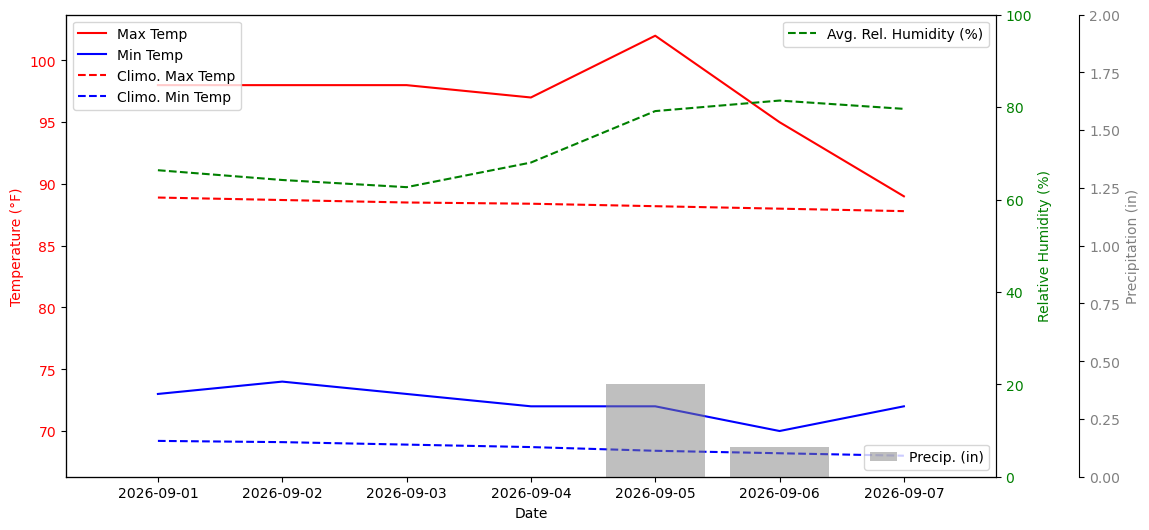

In [8]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(daily_df['max_temp_f'], color='red', label='Max Temp')
ax1.plot(daily_df['min_temp_f'], color='blue', label='Min Temp')
ax1.plot(daily_df['climo_high_f'], color='red', label='Climo. Max Temp', linestyle='--')
ax1.plot(daily_df['climo_low_f'], color='blue', label='Climo. Min Temp', linestyle='--')
ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature (°F)', color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.legend(loc='upper left')

# Create a secondary y-axis for humidity
ax2 = ax1.twinx()
ax2.plot(daily_df['avg_rh'], color='green', linestyle='--', label='Avg. Rel. Humidity (%)')
ax2.set_ylim(0, 100)
ax2.set_ylabel('Relative Humidity (%)', color='green')
ax2.tick_params(axis='y', labelcolor='green')
ax2.legend(loc='upper right')

# Create a third y-axis for precipitation (can also be a bar plot)
ax3 = ax1.twinx()
# Offset the spine of ax3 to the right to avoid overlap with ax2
ax3.spines['right'].set_position(('outward', 60))
ax3.bar(daily_df.index,daily_df['precip_in'], color='grey', alpha=0.5, width=0.8, label='Precip. (in)')
ax3.set_ylabel('Precipitation (in)', color='gray')
ax3.set_ylim(0,2)
ax3.tick_params(axis='y', labelcolor='gray')
ax3.legend(loc='lower right')

plt.show()

2025-08-18
07:00:00
16:00:00
20:00:00
2025-08-19
07:00:00
16:00:00
20:00:00
2025-08-20
07:00:00
16:00:00
20:00:00
2025-09-23
07:00:00
16:00:00
20:00:00
2025-09-24
07:00:00
16:00:00
20:00:00


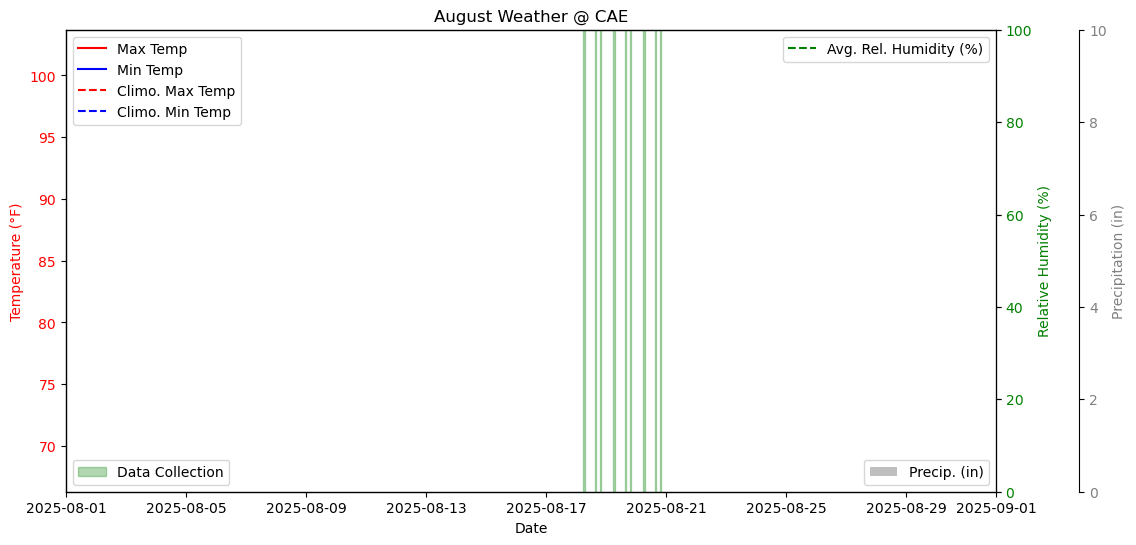

In [9]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(daily_df['max_temp_f'], color='red', label='Max Temp')
ax1.plot(daily_df['min_temp_f'], color='blue', label='Min Temp')
ax1.plot(daily_df['climo_high_f'], color='red', label='Climo. Max Temp', linestyle='--')
ax1.plot(daily_df['climo_low_f'], color='blue', label='Climo. Min Temp', linestyle='--')
ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature (°F)', color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.legend(loc='upper left')

# Create a secondary y-axis for humidity
ax2 = ax1.twinx()
ax2.plot(daily_df['avg_rh'], color='green', linestyle='--', label='Avg. Rel. Humidity (%)')
ax2.set_ylim(0, 100)
ax2.set_ylabel('Relative Humidity (%)', color='green')
ax2.tick_params(axis='y', labelcolor='green')
ax2.legend(loc='upper right')

# Create a third y-axis for precipitation (can also be a bar plot)
ax3 = ax1.twinx()
# Offset the spine of ax3 to the right to avoid overlap with ax2
ax3.spines['right'].set_position(('outward', 60))
ax3.bar(daily_df.index,daily_df['precip_in'], color='grey', alpha=0.5, width=0.8, label='Precip. (in)')
ax3.set_ylabel('Precipitation (in)', color='gray')
ax3.set_ylim(0,10)
ax3.tick_params(axis='y', labelcolor='gray')
ax3.legend(loc='lower right')

ax4 = ax1.twinx()
first_span = True
# plt.figure(figsize=(10,6))
for d in days:
    print(d)
    for p in periods:
        print(periods[p][1])
        start_p = f'{d} {periods[p][0]}'
        start_p = pd.to_datetime(start_p)
        end_p = f'{d} {periods[p][1]}'
        end_p = pd.to_datetime(end_p)
        if first_span:
            ax4.axvspan(start_p, end_p, color='green', alpha=0.3, zorder=0, label='Data Collection')
            first_span = False
        else:
            ax4.axvspan(start_p, end_p, color='green', alpha=0.3, zorder=0)
ax4.legend(loc='lower left')
ax4.tick_params(axis='y', labelright=False)

plt.title('August Weather @ CAE')
plt.xlim(pd.to_datetime('2025-08-01'),pd.to_datetime('2025-09-01')) 
plt.show()

Make plots on hourly data instead.

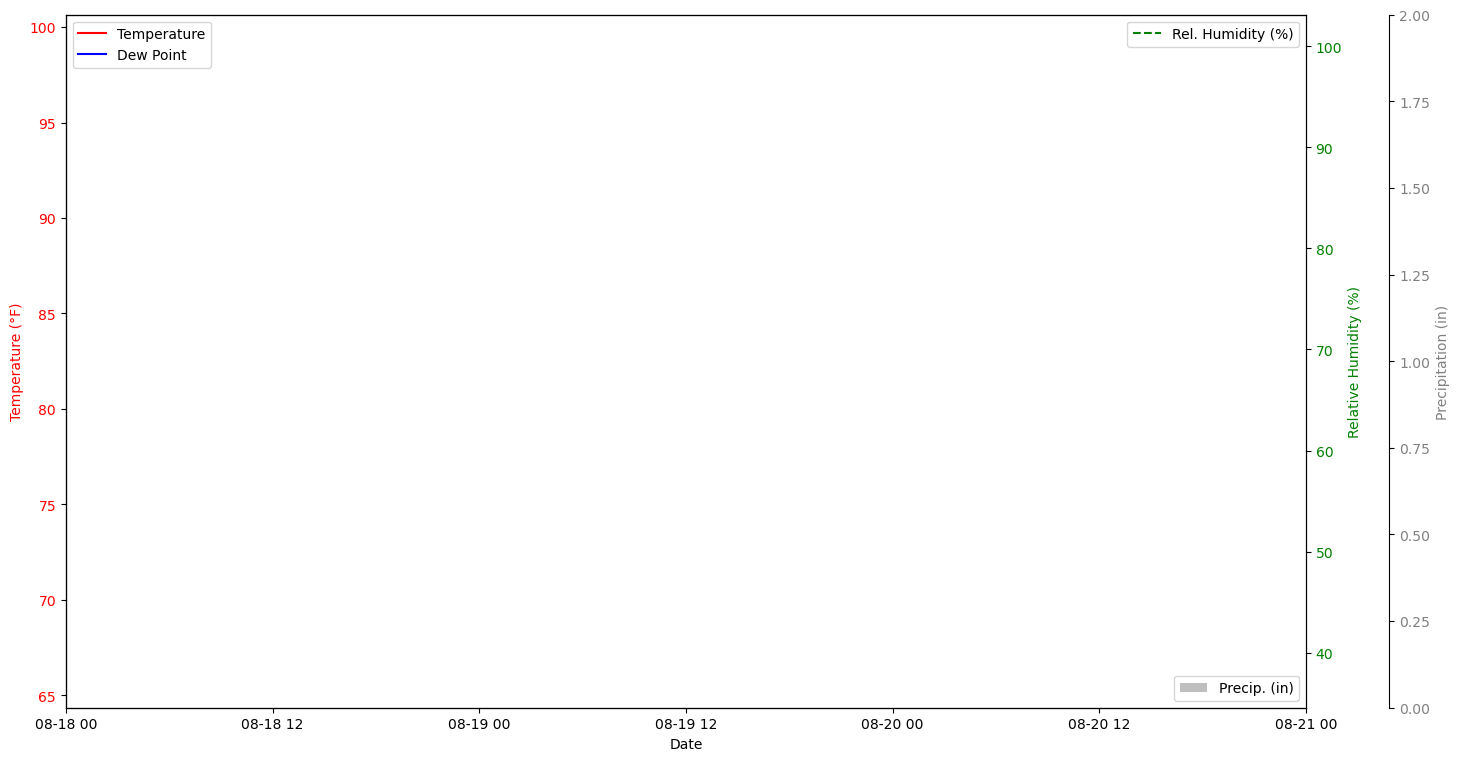

In [10]:
# Create the plot
start = pd.to_datetime('2025-08-18')
end = pd.to_datetime('2025-08-21')

fig, ax1 = plt.subplots(figsize=(16, 9))

ax1.plot(hourly_df['tmpf'], color='red', label='Temperature')
ax1.plot(hourly_df['dwpf'], color='blue', label='Dew Point')

ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature (°F)', color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.legend(loc='upper left')

# Create a secondary y-axis for humidity
ax2 = ax1.twinx()
ax2.plot(hourly_df['relh'], color='green', linestyle='--', label='Rel. Humidity (%)')
# ax2.set_ylim(0, 100)
ax2.set_ylabel('Relative Humidity (%)', color='green')
ax2.tick_params(axis='y', labelcolor='green')
ax2.legend(loc='upper right')

# Create a third y-axis for precipitation (can also be a bar plot)
ax3 = ax1.twinx()
# Offset the spine of ax3 to the right to avoid overlap with ax2
ax3.spines['right'].set_position(('outward', 60))
width=(end-start).days*24*60/2
width = dt.timedelta(minutes=10)
ax3.bar(hourly_df.index,hourly_df['p01i'], color='grey', alpha=0.5, width=width, label='Precip. (in)') # , width=0.8
ax3.set_ylabel('Precipitation (in)', color='gray')
ax3.set_ylim(0,2)
ax3.tick_params(axis='y', labelcolor='gray')
ax3.legend(loc='lower right')

plt.xlim(start, end) 
plt.show()

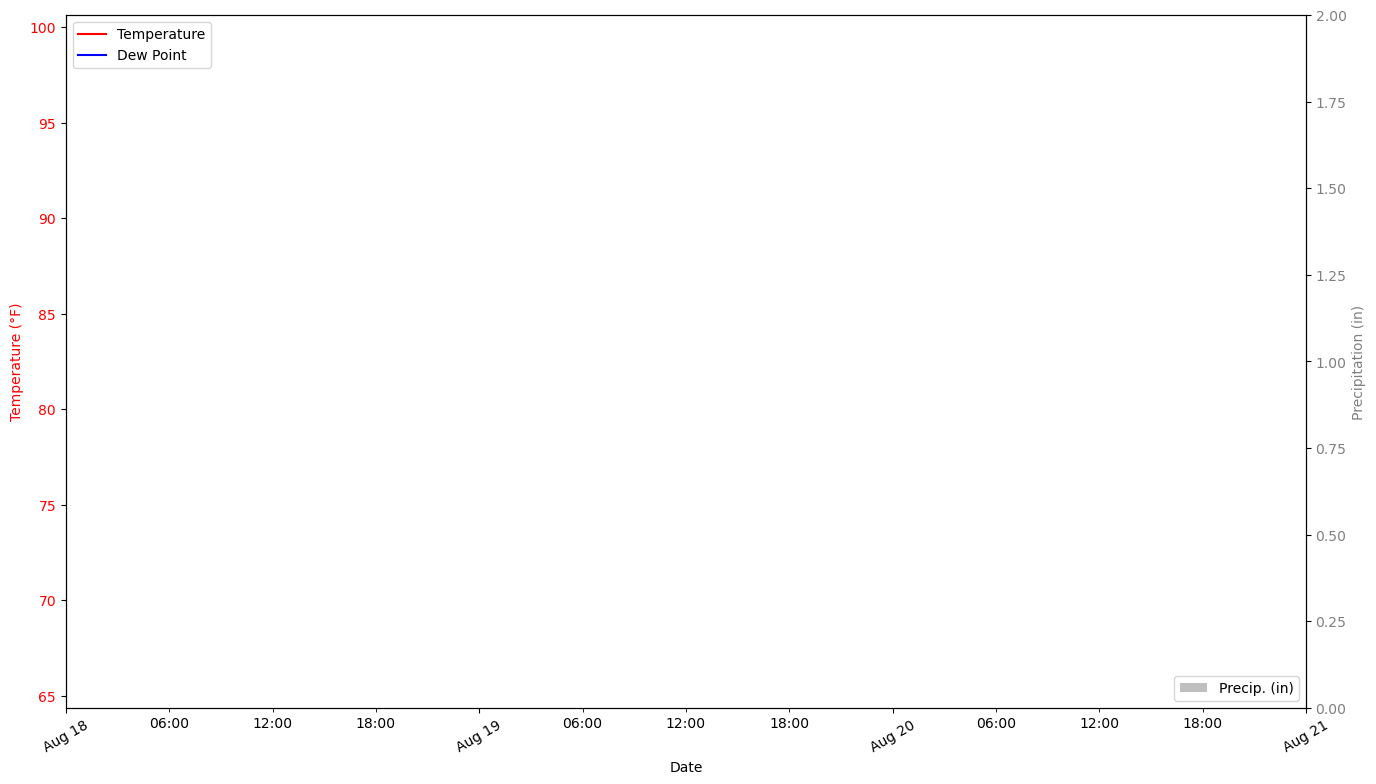

In [11]:
# Create the plot
start = pd.to_datetime('2025-08-18')
end = pd.to_datetime('2025-08-21')

fig, ax1 = plt.subplots(figsize=(16, 9))

# Set the major and minor x-axis marks
major_locator = mdates.DayLocator()
major_formatter = mdates.DateFormatter('%b %d')

minor_locator = mdates.HourLocator(byhour=[6, 12, 18])
minor_formatter = mdates.DateFormatter('%H:00')

ax1.tick_params(axis='x', which='major', rotation=30)


ax1.xaxis.set_major_locator(major_locator)
ax1.xaxis.set_major_formatter(major_formatter)
# Apply the formatter
ax1.xaxis.set_minor_formatter(minor_formatter)

ax1.xaxis.set_minor_locator(minor_locator)
ax1.tick_params(axis='x', which='minor', length=3)


ax1.plot(hourly_df['tmpf'], color='red', label='Temperature')
ax1.plot(hourly_df['dwpf'], color='blue', label='Dew Point')

ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature (°F)', color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.legend(loc='upper left')

# Create a third y-axis for precipitation (can also be a bar plot)
ax2 = ax1.twinx()
# Offset the spine of ax3 to the right to avoid overlap with ax2
# ax2.spines['right'].set_position(('outward', 60))
width=(end-start).days*24*60/2
width = dt.timedelta(minutes=10)
ax2.bar(hourly_df.index,hourly_df['p01i'], color='grey', alpha=0.5, width=width, label='Precip. (in)') # , width=0.8
ax2.set_ylabel('Precipitation (in)', color='gray')
ax2.set_ylim(0,2)
ax2.tick_params(axis='y', labelcolor='gray')
ax2.legend(loc='lower right')

plt.xlim(start, end) 
plt.show()

2025-08-18
07:00:00
16:00:00
20:00:00
2025-08-19
07:00:00
16:00:00
20:00:00
2025-08-20
07:00:00
16:00:00
20:00:00
2025-09-23
07:00:00
16:00:00
20:00:00
2025-09-24
07:00:00
16:00:00
20:00:00


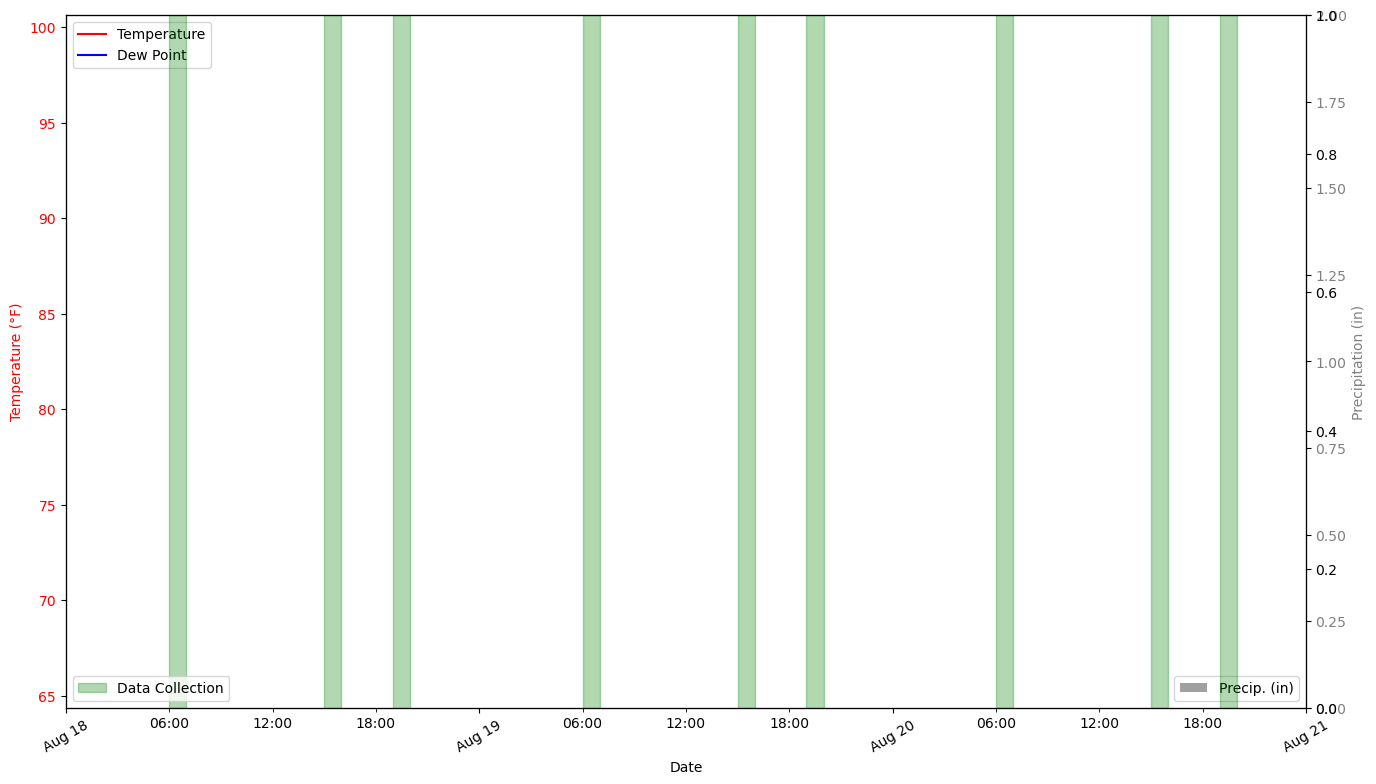

In [12]:
# Create the plot
start = pd.to_datetime('2025-08-18')
end = pd.to_datetime('2025-08-21')

fig, ax1 = plt.subplots(figsize=(16, 9))

# Set the major and minor x-axis marks
major_locator = mdates.DayLocator()
major_formatter = mdates.DateFormatter('%b %d')

minor_locator = mdates.HourLocator(byhour=[6, 12, 18])
minor_formatter = mdates.DateFormatter('%H:00')

ax1.tick_params(axis='x', which='major', rotation=30)


ax1.xaxis.set_major_locator(major_locator)
ax1.xaxis.set_major_formatter(major_formatter)
# Apply the formatter
ax1.xaxis.set_minor_formatter(minor_formatter)

ax1.xaxis.set_minor_locator(minor_locator)
ax1.tick_params(axis='x', which='minor', length=3)


ax1.plot(hourly_df['tmpf'], color='red', label='Temperature')
ax1.plot(hourly_df['dwpf'], color='blue', label='Dew Point')

ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature (°F)', color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.legend(loc='upper left')

# Create a third y-axis for precipitation (can also be a bar plot)
ax2 = ax1.twinx()
# Offset the spine of ax3 to the right to avoid overlap with ax2
# ax2.spines['right'].set_position(('outward', 60))
width=(end-start).days*24*60/2
width = dt.timedelta(minutes=10)
ax2.bar(hourly_df.index,hourly_df['p01i'], color='grey', alpha=0.75, width=width, label='Precip. (in)') # , width=0.8
ax2.set_ylabel('Precipitation (in)', color='gray')
ax2.set_ylim(0,2)
ax2.tick_params(axis='y', labelcolor='gray')
ax2.legend(loc='lower right')

ax3 = ax1.twinx()
first_span = True
# plt.figure(figsize=(10,6))
for d in days:
    print(d)
    for p in periods:
        print(periods[p][1])
        start_p = f'{d} {periods[p][0]}'
        start_p = pd.to_datetime(start_p)
        end_p = f'{d} {periods[p][1]}'
        end_p = pd.to_datetime(end_p)
        if first_span:
            ax3.axvspan(start_p, end_p, color='green', alpha=0.3, zorder=0, label='Data Collection')
            first_span = False
        else:
            ax3.axvspan(start_p, end_p, color='green', alpha=0.3, zorder=0)
ax3.legend(loc='lower left')
        # only show 1 label.

plt.xlim(start, end) 
plt.show()

In [13]:
periods['am']

('06:00:00', '07:00:00')

In [14]:
days

['2025-08-18', '2025-08-19', '2025-08-20', '2025-09-23', '2025-09-24']